## Setup: seed & reproducibility

Seluruh keacakan dikunci agar hasil bisa diulang:
- `torch.manual_seed(67)` → inisialisasi bobot & sampling tensor PyTorch deterministik,
- `np.random.seed(67)` → shuffle / split NumPy deterministik.

Tanpa seed, tiap Run menghasilkan bobot awal $W_0$ berbeda sehingga kurva loss tidak bisa dibandingkan antar optimizer.

In [1]:
import math
from typing import NamedTuple

import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (
    balanced_accuracy_score,
    f1_score,
    confusion_matrix,
    classification_report,
)

SEED = 67
torch.manual_seed(SEED)
np.random.seed(SEED)

## 1. Membaca dataset

Dataset $D$ berukuran $n=32833$ baris $\times$ $27$ kolom. Setiap baris = satu lagu dengan 12 fitur audio numerik dan satu label $y \in \{\text{10 kelas kesehatan mental}\}$.

> `low_memory=False` dipakai agar pandas menebak tipe kolom dalam sekali baca (menghilangkan `DtypeWarning` pada kolom campuran seperti `raga_name`).

`df.head()` memperlihatkan nama kolom, skala tiap fitur (mis. `tempo` ratusan vs `danceability` $0$–$1$), dan isi label `Mental_Health_Label`.

In [2]:
df = pd.read_csv('Music_recommendation_withProperRagas.csv', low_memory=False)
df.head()

,track_id,track_name,track_artist,track_popularity,track_album_id,track_album_name,track_album_release_date,playlist_name,playlist_id,playlist_genre,...,acousticness,instrumentalness,liveness,valence,tempo,duration_ms,Mental_Health_Label,raga_name,raga_label,instrument
0,697MjF1454XKvZmTuqkWmD,I Miss You,Jeriqo,45,2vJ6FDg6ZMS56U8Wbiw2Oz,I Miss You,2019-02-05,Pop Hits 2000-2019,6mtYuOxzl58vSGnEDtZ9uB,edm,...,0.004910,0.000013,0.0816,0.415,174.026,216347,Normal/Unclassified,NaN,Bageshree,Unknown
1,3x2bXiU0o4WbsPkawXlfDA,Who Are You,The Who,17,6LRJF97hgXHj8uMLHyCDbh,Who Are You (Remastered),1978-08-18,House Of The Rising Sun,1bMYfBHYBCRHY5LGkjlpSy,rock,...,0.265000,0.003130,0.1060,0.489,156.371,378707,Normal/Unclassified,NaN,Yaman,Guitar/Drums
2,0jEaPBjFAWjQTMVouRwaHi,Happy,The Beef Seeds,30,4IQn9XpweytNX2cUe2NBUH,Keepin' it Beefy,2015-01-19,Bluegrass Covers,37i9dQZF1DX56crgoe4TG3,r&b,...,0.665000,0.000000,0.1270,0.932,86.529,218044,Bipolar (Mania),NaN,Kafi,Unknown
3,5EKUb1FKsyYVaSXb41YBIj,ONE,Rev Theory,35,0gGic19XvEiHKKWBV7M4YM,ONE,2020-01-15,Rock Hard,37i9dQZF1DWWJOmJ7nRx0C,rock,...,0.000006,0.000000,0.3030,0.520,90.016,208196,Normal/Unclassified,NaN,Bageshree,Guitar/Drums
4,300DUx4tdtCdGEUXR032jA,Palace/Curse,The Internet,62,69g3CtOVg98TPOwqmI2K7Q,Ego Death,2015-06-26,NEO-soul,3q3M4VCymcMoxJ3Tl7mRqN,r&b,...,0.035100,0.000727,0.2430,0.261,67.104,440013,Normal/Unclassified,NaN,Kafi,Unknown


## 2. Struktur & tipe data (`info`)

Total 27 kolom: 9 `float64` + 4 `int64` + 14 `str`. Yang dipakai model hanya 12 fitur numerik + 1 kolom label; sisanya (id lagu, nama playlist, raga, instrumen, …) adalah metadata.

In [3]:
df.info(verbose=True, show_counts=True)

<class 'pandas.DataFrame'>
RangeIndex: 32833 entries, 0 to 32832
Data columns (total 27 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   track_id                  32833 non-null  str    
 1   track_name                32828 non-null  str    
 2   track_artist              32828 non-null  str    
 3   track_popularity          32833 non-null  int64  
 4   track_album_id            32833 non-null  str    
 5   track_album_name          32828 non-null  str    
 6   track_album_release_date  32833 non-null  str    
 7   playlist_name             32833 non-null  str    
 8   playlist_id               32833 non-null  str    
 9   playlist_genre            32833 non-null  str    
 10  playlist_subgenre         32833 non-null  str    
 11  danceability              32833 non-null  float64
 12  energy                    32833 non-null  float64
 13  key                       32833 non-null  int64  
 14  loudness         

## 3. Data hilang (`isna`)

Menghitung $\sum_i \mathbf{1}[x_i = \text{NaN}]$ per kolom. Kolom audio & label lengkap ($0$ hilang); yang kosong hanya metadata (`raga_name` 32827 kosong) sehingga tidak mengganggu training.

In [4]:
df.isna().sum()[df.isna().sum() > 0]

track_name              5
track_artist            5
track_album_name        5
raga_name           32827
dtype: int64

## 4. Definisi fitur $X$ dan label $y$

$$X \in \mathbb{R}^{n \times 12}, \qquad y \in \{0,\dots,9\}^n$$

12 fitur audio (skala beda jauh — alasan perlunya standardisasi di §8). `target` ditulis sebagai **string** (bukan list) agar `y` berupa Series 1-D dan tidak memicu `DataConversionWarning` di `LabelEncoder`.

In [5]:
features = [
    'danceability', 'energy', 'key', 'loudness',
    'mode', 'speechiness', 'acousticness',
    'instrumentalness', 'liveness', 'valence',
    'tempo', 'duration_ms'
]

target = 'Mental_Health_Label'  # plain string -> 1-D Series (avoids DataConversionWarning)

## 5. Matriks $X$ dan vektor $y$

`X = df[features]` mengambil blok numerik $n \times 12$, `y = df[target]` mengambil vektor label $n \times 1$. Keduanya masih berupa DataFrame/Series pandas — konversi ke tensor dilakukan di `load_data` (§8).

In [6]:
X = df[features]
y = df[target]

Disimpan ke: distribusi_label.png


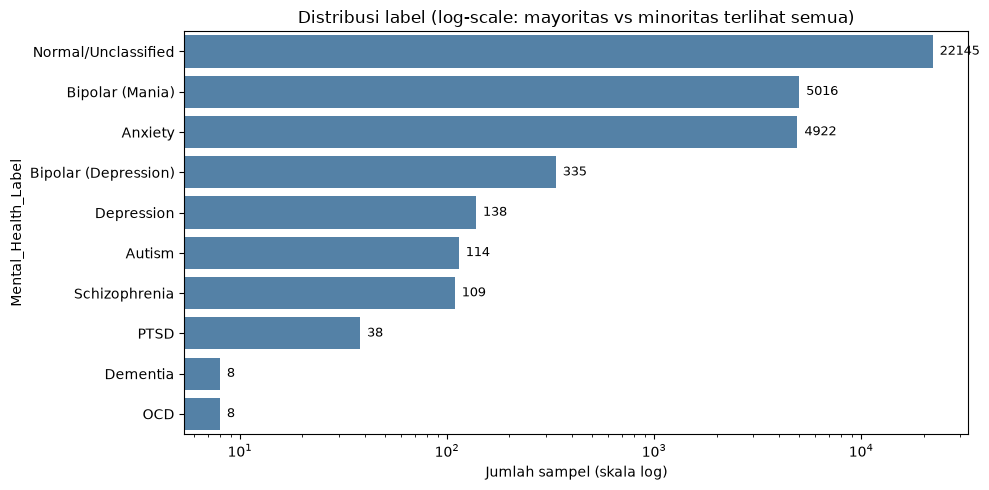

Disimpan ke: distribusi_fitur.png


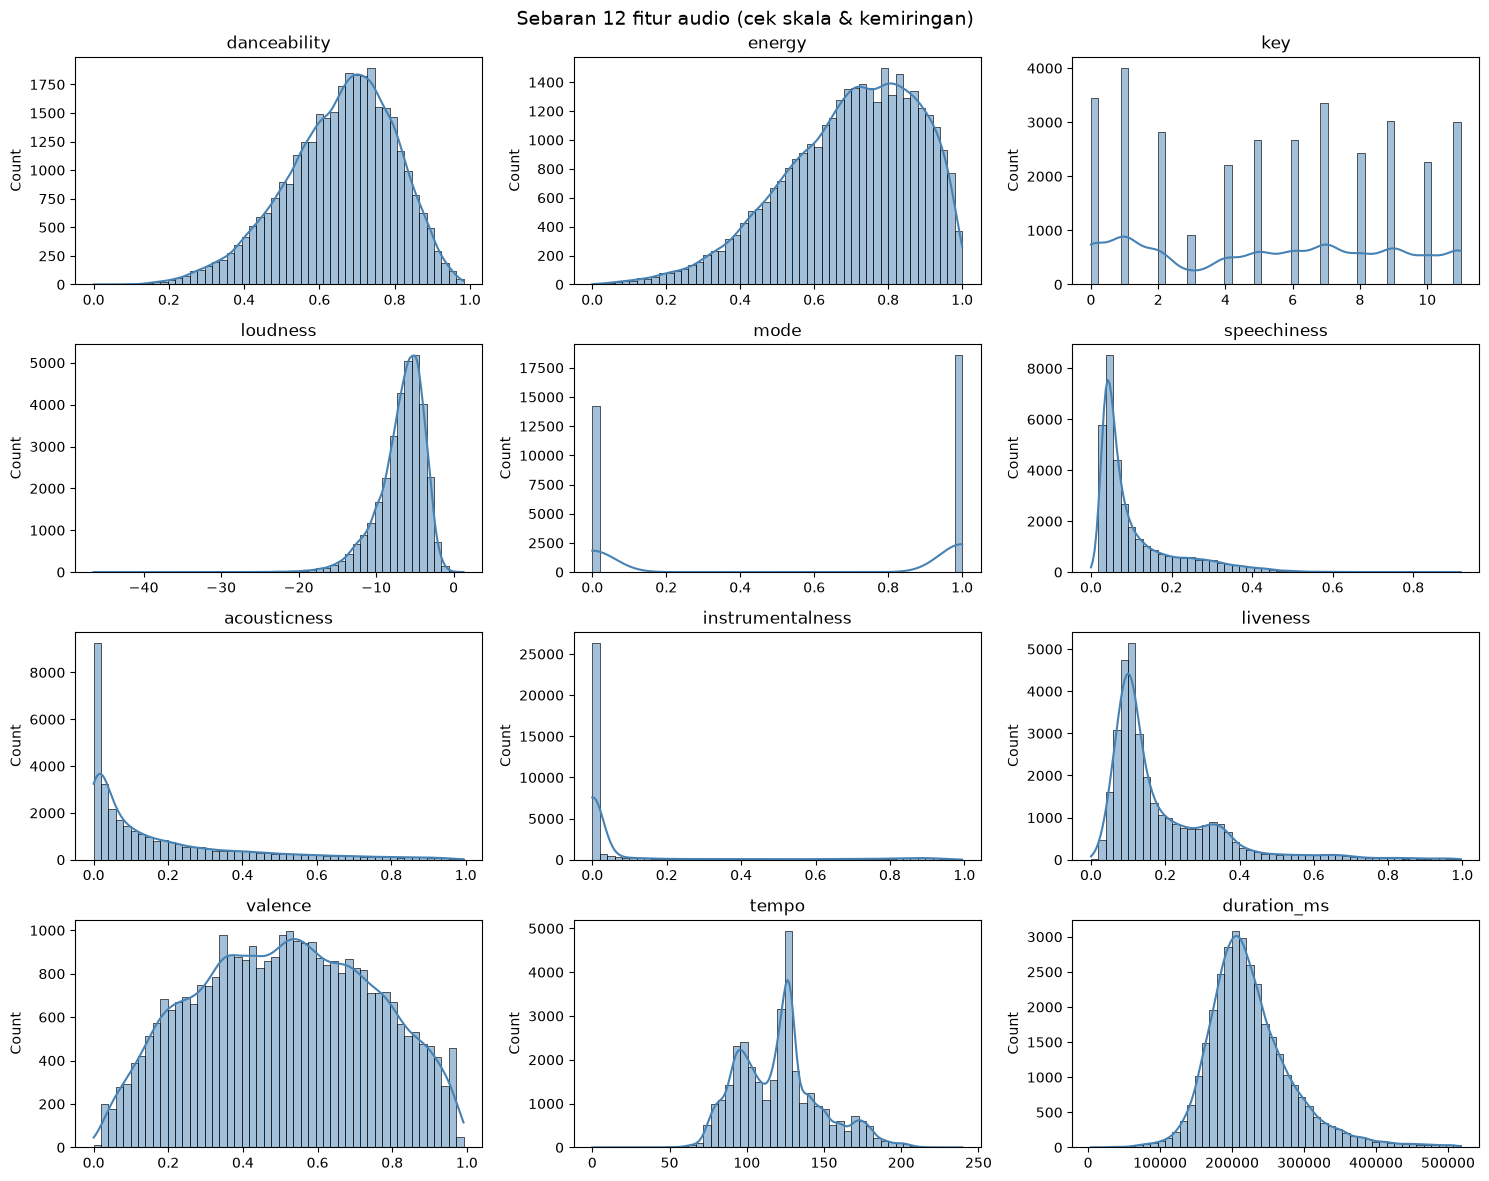

In [7]:
counts = y.value_counts()
plt.figure(figsize=(10, 5))
sns.barplot(x=counts.values, y=counts.index, orient="h", color="steelblue")
plt.xscale("log")
for i, v in enumerate(counts.values):
    plt.text(v * 1.08, i, str(v), va="center", fontsize=9)
plt.xlabel("Jumlah sampel (skala log)")
plt.ylabel("Mental_Health_Label")
plt.title("Distribusi label (log-scale: mayoritas vs minoritas terlihat semua)")
plt.tight_layout()
print("Disimpan ke: distribusi_label.png")
plt.show()

fig, axes = plt.subplots(4, 3, figsize=(15, 12))
for ax, col in zip(axes.flat, features):
    sns.histplot(df[col], bins=50, kde=True, ax=ax, color="steelblue")
    ax.set_title(col)
    ax.set_xlabel("")
fig.suptitle("Sebaran 12 fitur audio (cek skala & kemiringan)", fontsize=14)
plt.tight_layout()
print("Disimpan ke: distribusi_fitur.png")
plt.show()

## 6. Sebaran label: data timpang!

$$\text{mayoritas} = \frac{22145}{32833} \approx 0{,}674$$

Menebak `"Normal/Unclassified"` terus-menerus saja sudah berakurasi $\approx 67\%$, sementara kelas minoritas (`OCD`, `Dementia` masing-masing $8$ sampel) nyaris tak terwakili. Inilah alasan akurasi biasa **menipu** dan kita butuh *balanced accuracy* + *macro-F1* (§13). `stratify` pada split (§8) menjaga proporsi ini di tiap subset.

In [8]:
y.value_counts()

Mental_Health_Label
Normal/Unclassified     22145
Bipolar (Mania)          5016
Anxiety                  4922
Bipolar (Depression)      335
Depression                138
Autism                    114
Schizophrenia             109
PTSD                       38
Dementia                    8
OCD                         8
Name: count, dtype: int64

## 7. Korelasi antar fitur 

$$r_{jk} = \frac{\sum_i (x_{ij}-\bar{x}_j)(x_{ik}-\bar{x}_k)}
{\sqrt{\sum_i (x_{ij}-\bar{x}_j)^2}\sqrt{\sum_i (x_{ik}-\bar{x}_k)^2}} \in [-1, 1]$$

$|r| \approx 1$ berarti dua fitur membawa informasi yang sama (redundan); $|r| \approx 0$ berarti independen. Heatmap dipakai untuk memastikan tidak ada fitur yang identik/duplikat sebelum training.

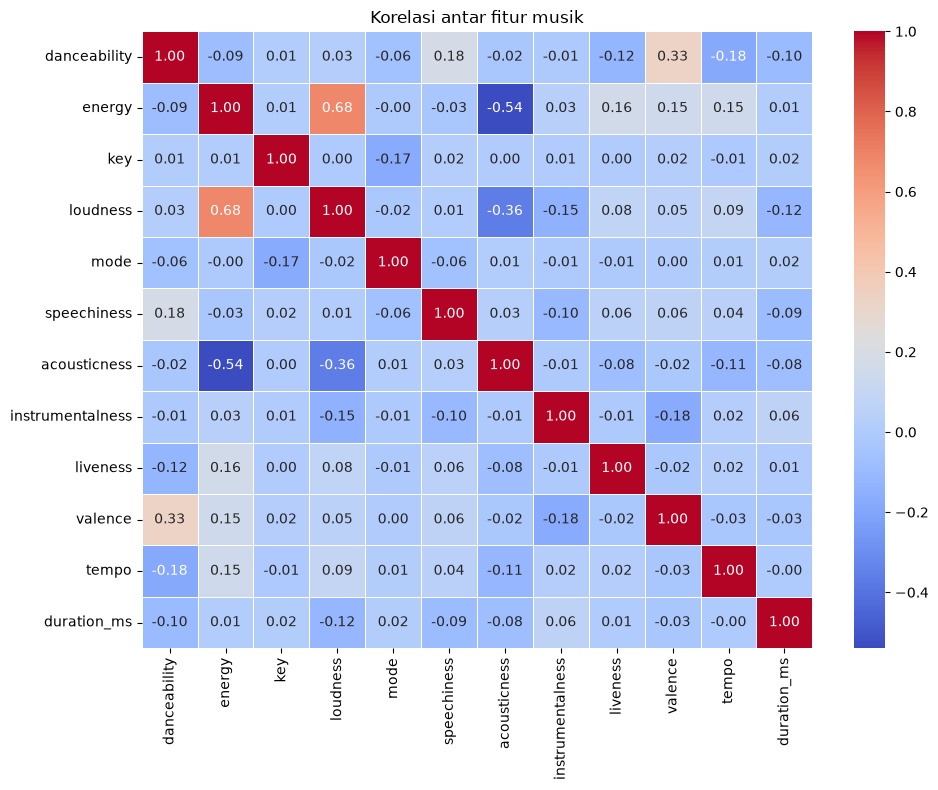

In [9]:
correlation_matrix = X.corr()
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Korelasi antar fitur musik")
plt.tight_layout()
plt.show()

## 8. `load_data`: encode → split 70/15/15 → standarisasi → tensor

1. **Encode.** Label teks $y^{\text{teks}}$ dipetakan ke $y \in \{0,\dots,9\}$ via `LabelEncoder`.
2. **Split bertingkat + stratify** (proporsi kelas dipertahankan):
   $$n_{\text{latih}} = 22983,\quad n_{\text{val}} = 4925,\quad n_{\text{uji}} = 4925$$
   Aturan pakai: *tuning* ($lr$, `sizes`, aktivasi) hanya melihat **validasi**; **uji** dibuka sekali di akhir.
3. **Standarisasi** ($z$-score) per fitur $j$, dengan $\mu_j, \sigma_j$ dihitung **hanya dari data latih**:
   $$\tilde{x}_{ij} = \frac{x_{ij} - \mu_j}{\sigma_j}, \qquad \mu_j = 0,\ \sigma_j = 1\ \text{setelah transformasi}$$
   Tanpa ini, fitur berskala besar (`duration_ms` $\sim 10^5$) mendominasi gradien dan training tidak stabil.
4. **Tensor.** $X$ → `float32`, $y$ → `long` (syarat `cross_entropy`).

`df` yang sudah dibaca di §1 diteruskan ke `load_data` — jadi CSV **tidak dibaca dua kali**, dan data yang di-EDA identik dengan data yang dilatih. Hasilnya satu bundel `Splits` (6 tensor + nama kelas).

In [10]:
class Splits(NamedTuple):
    Xtr: torch.Tensor
    ytr: torch.Tensor
    Xval: torch.Tensor
    yval: torch.Tensor
    Xte: torch.Tensor
    yte: torch.Tensor
    classes: list[str]


def load_data(df, test_size=0.15, val_size=0.15, random_state=SEED):
    """Encode labels, split 70/15/15, standardize (fit on train only), return Splits."""
    X_raw = df[features].to_numpy(dtype=np.float32)
    encoder = LabelEncoder()
    y_encoded = encoder.fit_transform(df[target])

    # Split off the test set first, then carve validation out of the remainder
    X_rest, X_te, y_rest, y_te = train_test_split(
        X_raw, y_encoded, test_size=test_size,
        random_state=random_state, stratify=y_encoded,
    )
    val_rel = val_size / (1 - test_size)  # validation share relative to the remainder
    X_tr, X_val, y_tr, y_val = train_test_split(
        X_rest, y_rest, test_size=val_rel,
        random_state=random_state, stratify=y_rest,
    )

    scaler = StandardScaler()
    X_tr = scaler.fit_transform(X_tr).astype(np.float32)
    X_val = scaler.transform(X_val).astype(np.float32)
    X_te = scaler.transform(X_te).astype(np.float32)

    print(f"Bagi data -> latih {len(X_tr)}, validasi {len(X_val)}, uji {len(X_te)}")
    return Splits(
        torch.from_numpy(X_tr), torch.from_numpy(y_tr).long(),
        torch.from_numpy(X_val), torch.from_numpy(y_val).long(),
        torch.from_numpy(X_te), torch.from_numpy(y_te).long(),
        list(encoder.classes_),
    )

## 9. Inisialisasi bobot `init_layer`

Untuk layer $W \in \mathbb{R}^{f_{\text{out}} \times f_{\text{in}}}$ dengan bias $b = 0$:
- **He** (untuk ReLU): $W_{ij} \sim \mathcal{N}\!\left(0,\, \frac{2}{f_{\text{in}}}\right)$ — menjaga $\mathrm{Var}(h^{(l)}) \approx \mathrm{Var}(h^{(l-1)})$ karena ReLU mematikan separuh aktivasi;
- **Xavier** (untuk tanh/sigmoid): $W_{ij} \sim \mathcal{N}\!\left(0,\, \frac{2}{f_{\text{in}}+f_{\text{out}}}\right)$ — menjaga variansi maju **dan** gradien mundur;
- `small/large/const/zero`: varian kecil ($0{,}01$), besar ($1$), konstan ($0{,}1$), nol — untuk eksperimen divergensi.

`"default"` membiarkan inisialisasi bawaan PyTorch $U(-1/\sqrt{f_{\text{in}}},\, 1/\sqrt{f_{\text{in}}})$.

In [11]:
def init_layer(layer: nn.Linear, init: str = "he"):
    """Re-initialize one nn.Linear in place.

    Options for `init`:
      default = keep PyTorch's default init, small = N(0, 0.01),
      const = 0.1, zero = 0, large = N(0, 1.0),
      xavier / he = Gaussian scaled by layer size.
    Bias is always zeroed (except in "default" mode).
    """
    W, b = layer.weight, layer.bias
    fan_out, fan_in = W.shape  # PyTorch stores weights as [out, in]

    with torch.no_grad():
        if init == "default":
            return
        elif init == "zero":
            W.zero_()
        elif init == "const":
            W.fill_(0.1)
        elif init == "small":
            W.normal_(0, 0.01)
        elif init == "large":
            W.normal_(0, 1.0)
        elif init == "xavier":
            W.normal_(0, math.sqrt(2.0 / (fan_in + fan_out)))
        elif init == "he":
            W.normal_(0, math.sqrt(2.0 / fan_in))
        else:
            raise ValueError(f"Unknown init: {init}")
        b.zero_()

## 10. Model MLP: forward, loss, dan aktivasi dinamis

**Forward.** Untuk `sizes` $=(d_0, d_1, \dots, d_L)$, tiap hidden layer:
$$z^{(l)} = W^{(l)} h^{(l-1)} + b^{(l)}, \qquad h^{(l)} = \sigma(z^{(l)}),\quad l = 1,\dots,L-1$$
dengan $h^{(0)} = x$ dan $\sigma \in \{\mathrm{ReLU}, \tanh, \mathrm{sigmoid}, \dots\}$ dipilih via `activation`. Contoh `sizes=(12,64,32,10)`:
$$12 \xrightarrow{\ \sigma\ } 64 \xrightarrow{\ \sigma\ } 32 \longrightarrow 10\ \text{logits}$$

**Kenapa layer terakhir tanpa aktivasi?** Loss-nya cross-entropy dengan softmax di dalamnya:
$$\mathcal{L} = -\frac{1}{N}\sum_{i=1}^{N} \log \frac{e^{z_{i,y_i}}}{\sum_{k=1}^{10} e^{z_{i,k}}}$$
Memberi softmax/sigmoid/ReLU sebelumnya = aktivasi ganda (gradien rusak). Prediksi cukup $\hat{y}_i = \arg\max_k z_{i,k}$ karena $\arg\max$ invarian terhadap softmax.

In [12]:
def _get_activation(name):
    options = {
        "relu": F.relu,
        "tanh": torch.tanh,
        "sigmoid": torch.sigmoid,
        "leaky_relu": F.leaky_relu,
        "gelu": F.gelu,
        "elu": F.elu,
    }
    if callable(name):  # a custom function (e.g. F.silu) is also accepted
        return name
    try:
        return options[name]
    except KeyError:
        raise ValueError(f"Unknown activation: {name}. Choose from: {sorted(options)}")


class MLP(nn.Module):
    def __init__(self, sizes=(12, 128, 64, 10), init="he", seed=SEED, activation="relu"):
        super().__init__()
        torch.manual_seed(seed)  # for reproducibility
        self.act = _get_activation(activation)
        self.layers = nn.ModuleList(
            nn.Linear(n_in, n_out) for n_in, n_out in zip(sizes[:-1], sizes[1:])
        )
        for layer in self.layers:
            init_layer(layer, init)

    @property
    def params(self):
        """Flat parameter list (in registration order) for autograd.grad / manual optimizers."""
        return list(self.parameters())

    def forward(self, x):
        """Return logits only; the last layer has no activation (softmax lives in cross_entropy)."""
        for layer in self.layers[:-1]:
            x = self.act(layer(x))
        return self.layers[-1](x)

    def loss_and_grads(self, x, y):
        """Compute the loss and its gradients (used at every training step)."""
        loss = F.cross_entropy(self.forward(x), y)
        return loss.item(), list(torch.autograd.grad(loss, self.params))

    @torch.no_grad()
    def loss(self, x, y):
        return F.cross_entropy(self.forward(x), y).item()

    @torch.no_grad()
    def accuracy(self, x, y):
        preds = self.forward(x).argmax(dim=1)
        return (preds == y).float().mean().item()

## 11. Optimizer manual (tanpa `torch.optim`, untuk belajar)

Semua mengembalikan `step(params, grads)` dengan gradien $g_t = \nabla_w \mathcal{L}_{\text{batch}}$:
- **SGD:** $w \leftarrow w - \eta\, g_t$
- **Momentum:** $v \leftarrow \beta v + g_t,\quad w \leftarrow w - \eta\, v$ — meredam osilasi ($\beta = 0{,}9$);
- **RMSprop:** $s \leftarrow \rho s + (1-\rho)\, g_t^2,\quad w \leftarrow w - \eta\, g_t / (\sqrt{s} + \epsilon)$ — *learning rate* adaptif per bobot;
- **Adam** = keduanya + koreksi bias: $m_t, v_t$ dibagi $(1-\beta_1^t)$, $(1-\beta_2^t)$ agar tak bias ke $0$ di step awal.

In [13]:
def make_sgd(lr=0.1):
    """Plain SGD: w -= lr * gradient."""
    def step(params, grads):
        with torch.no_grad():
            for p, g in zip(params, grads):
                p -= lr * g
    return step


def make_momentum(lr=0.01, beta=0.9):
    """SGD + momentum: reuse the previous direction to reduce oscillation."""
    velocity = {}

    def step(params, grads):
        with torch.no_grad():
            for i, (p, g) in enumerate(zip(params, grads)):
                velocity[i] = beta * velocity.get(i, 0) + g
                p -= lr * velocity[i]
    return step


def make_rmsprop(lr=0.001, rho=0.99, eps=1e-8):
    """RMSprop: a per-weight adaptive learning rate."""
    sq_avg = {}

    def step(params, grads):
        with torch.no_grad():
            for i, (p, g) in enumerate(zip(params, grads)):
                sq_avg[i] = rho * sq_avg.get(i, 0) + (1 - rho) * g * g
                p -= lr * g / (torch.sqrt(sq_avg[i]) + eps)
    return step


def make_adam(lr=0.001, beta1=0.9, beta2=0.999, eps=1e-8, bias_correction=True):
    """Adam = momentum + RMSprop + bias correction for the early steps."""
    m, v = {}, {}
    step_count = 0

    def step(params, grads):
        nonlocal step_count
        step_count += 1
        with torch.no_grad():
            for i, (p, g) in enumerate(zip(params, grads)):
                m[i] = beta1 * m.get(i, 0) + (1 - beta1) * g
                v[i] = beta2 * v.get(i, 0) + (1 - beta2) * g * g
                if bias_correction:
                    m_hat = m[i] / (1 - beta1 ** step_count)
                    v_hat = v[i] / (1 - beta2 ** step_count)
                else:
                    m_hat, v_hat = m[i], v[i]
                p -= lr * m_hat / (torch.sqrt(v_hat) + eps)
    return step

## 12. `train`: minibatch + deteksi divergensi

Melatih satu model untuk `epochs` pass penuh atas data latih. Tiap update: ambil minibatch $B=64$ (reshuffle tiap epoch) → `loss_and_grads` → `step(params, grads)`; di akhir tiap epoch dicatat loss & akurasi train/val. Fungsi mengembalikan `TrainResult` (`train_loss`, `val_loss`, `train_acc`, `val_acc`, `test_acc`, `epoch_curves`, `model`, `diverged`). Run dengan loss/bobot non-finit ($\mathrm{NaN}/\infty$) ditandai `diverged=True` (`loss = \infty`).

Semua optimizer memakai jalur training yang sama ini — tidak ada yang diperlakukan khusus.

In [14]:
class TrainResult(NamedTuple):
    train_loss: float
    val_loss: float
    train_acc: float
    val_acc: float
    test_acc: float
    epoch_curves: dict[str, list[float]]  # train/val loss & acc per epoch
    model: nn.Module
    diverged: bool


def _make_model(data: Splits, sizes, init: str, activation, seed: int) -> MLP:
    """Build an MLP whose first/last dims are inferred from the data."""
    sizes = [data.Xtr.shape[1], *sizes[1:-1], int(data.ytr.max().item()) + 1]
    return MLP(tuple(sizes), init, seed, activation)


def _minibatches(n, batch_size, rng):
    """Infinite shuffled minibatch index generator; reshuffles at each epoch."""
    while True:
        order = rng.permutation(n)
        for s in range(0, n, batch_size):
            yield torch.as_tensor(order[s:s + batch_size])


def _diverged(batch_loss, params):
    return not math.isfinite(batch_loss) or not all(torch.isfinite(p).all() for p in params)


def train(opt_factory, data, *, epochs=20, batch_size=64, sizes=(12, 128, 64, 10),
          init="he", activation="relu", seed=SEED):
    """Train one model for `epochs` full passes over the TRAIN data.

    Minibatches come from TRAIN data only; test data stays untouched until the end.
    Returns a TrainResult with per-epoch curves and a `diverged` flag (NaN/inf loss or weights).
    """
    model = _make_model(data, sizes, init, activation, seed)
    step_fn = opt_factory()
    rng = np.random.default_rng(1000 + seed)
    n, Xtr, ytr = len(data.Xtr), data.Xtr, data.ytr
    curves = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}

    def fail():
        return TrainResult(math.inf, math.inf, float("nan"), float("nan"),
                           float("nan"), curves, model, True)

    batches = _minibatches(n, batch_size, rng)
    for _ in range(epochs):
        for _ in range(math.ceil(n / batch_size)):
            idx = next(batches)
            loss, grads = model.loss_and_grads(Xtr[idx], ytr[idx])
            step_fn(model.params, grads)
            if _diverged(loss, model.params):
                return fail()
        curves["train_loss"].append(model.loss(Xtr, ytr))
        curves["val_loss"].append(model.loss(data.Xval, data.yval))
        curves["train_acc"].append(model.accuracy(Xtr, ytr))
        curves["val_acc"].append(model.accuracy(data.Xval, data.yval))

    train_loss = model.loss(Xtr, ytr)
    if not math.isfinite(train_loss):
        return fail()
    return TrainResult(
        train_loss, model.loss(data.Xval, data.yval),
        model.accuracy(Xtr, ytr), model.accuracy(data.Xval, data.yval),
        model.accuracy(data.Xte, data.yte),
        curves, model, False,
    )


def fit_status(train_acc, val_acc, train_loss, val_loss, gap_tol=0.03):
    """Klasifikasi Fit/Overfit sederhana dari gap train-val."""
    if not all(math.isfinite(v) for v in [train_acc, val_acc, train_loss, val_loss]):
        return "Diverged"
    gap = train_acc - val_acc
    if gap > gap_tol or val_loss > train_loss + 0.10:
        return "Overfit"
    if train_acc < 0.60 and val_acc < 0.60:
        return "Underfit"
    return "Fit"

## 13. Metrik jujur untuk data timpang

- **Akurasi:** $\mathrm{acc} = \frac{1}{N}\sum_i \mathbf{1}[\hat{y}_i = y_i]$ — menipu .
- **Balanced accuracy:** rata-rata recall per kelas, $\frac{1}{10}\sum_{c} \frac{\mathrm{TP}_c}{\mathrm{TP}_c + \mathrm{FN}_c}$ 
- **Macro-F1:** rata-rata $F_1$ per kelas, $F_{1,c} = \frac{2P_c R_c}{P_c + R_c}$ — kelas kecil bersuara sama besar dengan kelas besar (dengan `zero_division=0` untuk kelas tanpa prediksi benar).
- **Confusion matrix** $C \in \mathbb{N}^{10 \times 10}$, $C_{ab} = \#\{y=a, \hat{y}=b\}$ — menunjukkan kelas mana tertukar (diagonal = benar).

`predict` + `metric_summary` dipakai di §16 untuk menambah balanced accuracy & macro-F1 ke tabel ringkasan (dan memilih model terbaik), serta di §17 untuk classification report — supaya klaim "akurasi menipu" benar-benar diukur, bukan sekadar akurasi.

In [15]:
@torch.no_grad()
def predict(model, X):
    """Return the predicted classes (0..9) for a tensor batch."""
    return model(X).argmax(dim=1).cpu().numpy()


def metric_summary(y_true, y_pred):
    """Return an {accuracy, balanced_accuracy, macro_f1} dict from numpy arrays."""
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    return {
        "accuracy": float((y_true == y_pred).mean()),
        "balanced_accuracy": float(balanced_accuracy_score(y_true, y_pred)),
        "macro_f1": float(f1_score(y_true, y_pred, average="macro", zero_division=0)),
    }

## 14. Eksekusi split data

Menjalankan `load_data(df)`: hasil aktual $22983$ latih / $4925$ validasi / $4925$ uji, tiap tensor $X$ berdimensi $(\cdot \times 12)$.

In [16]:
data = load_data(df)
print(f"Latih: {tuple(data.Xtr.shape)}, validasi: {tuple(data.Xval.shape)}, "
      f"uji: {tuple(data.Xte.shape)}")

Bagi data -> latih 22983, validasi 4925, uji 4925
Latih: (22983, 12), validasi: (4925, 12), uji: (4925, 12)


## 15. Percobaan arsitektur MLP: cari ukuran terbaik

Sebelum membandingkan optimizer, tentukan dulu arsitekturnya. Beberapa kandidat `sizes` dilatih dengan optimizer tetap (Adam, $lr=10^{-3}$) dan **beberapa seed** satu seed bisa menipu karena variansi macro-F1 antar seed besar. Sel ini butuh beberapa menit.

Model dinilai dengan **macro-F1 validasi** (§13), bukan akurasi. Menariknya, arsitektur besar (mis. `256-128`, $37.514$ parameter) belum overfit di sini (gap train-val $\approx 2\%$), sedangkan arsitektur terlalu kecil jelas kalah jadi kapasitas bukan masalah, melainkan ketidakseimbangan kelas. `best_sizes` dipilih otomatis dan dipakai di §16.

In [17]:
ARCHS = {
    "32":         (12, 32, 10),
    "64-32":      (12, 64, 32, 10),
    "128":        (12, 128, 10),
    "128-64":     (12, 128, 64, 10),
    "256-128":    (12, 256, 128, 10),
    "256-128-64": (12, 256, 128, 64, 10),
}
ABLATION_SEEDS = [67, 68, 69]

abl_rows = []
for arch, szs in ARCHS.items():
    val_f1 = []
    for s in ABLATION_SEEDS:
        r = train(make_adam, data, epochs=20, sizes=szs, seed=s)
        val_f1.append(metric_summary(data.yval, predict(r.model, data.Xval))["macro_f1"])
    abl_rows.append({
        "Arsitektur": arch,
        "Params": sum(p.numel() for p in MLP(tuple(szs)).parameters()),
        "Val Macro-F1": float(np.mean(val_f1)),
        "std": float(np.std(val_f1)),
    })

abl_df = pd.DataFrame(abl_rows).sort_values("Val Macro-F1", ascending=False).set_index("Arsitektur")
print(f"Eksperimen Arsitektur (Adam lr=1e-3, {len(ABLATION_SEEDS)} seed, 20 epoch)")
print(abl_df.to_string(float_format="%.4f"))

BEST_ARCH = abl_df.index[0]
best_sizes = ARCHS[BEST_ARCH]
print(f"\nArsitektur terbaik (val macro-F1): {BEST_ARCH} -> sizes={best_sizes}")

Eksperimen Arsitektur (Adam lr=1e-3, 3 seed, 20 epoch)
            Params  Val Macro-F1    std
Arsitektur                             
128-64       10570        0.7107 0.0555
256-128      37514        0.7088 0.0539
256-128-64   45130        0.6612 0.0602
128           2954        0.5995 0.0077
64-32         3242        0.5992 0.0183
32             746        0.5141 0.0056

Arsitektur terbaik (val macro-F1): 128-64 -> sizes=(12, 128, 64, 10)


## 16. Laporan akhir: Tabel Ringkasan Kinerja Utama

Format akademis: Train Loss + Val Loss + Train/Val Acc berdampingan untuk deteksi *overfitting* langsung, ditambah **Bal. Acc** & **Macro-F1** (data uji) sebagai metrik jujur untuk data timpang (§13). Kolom Status diisi otomatis via `fit_status` (gap train-val > 3% atau val_loss >> train_loss = Overfit). Hyperparameter disamakan agar adil: batch=64, epochs=20, lr=1e-3 (Adam/RMSprop), lr=1e-2 (SGD/Momentum), loss=Cross-Entropy; arsitektur (`sizes`) memakai hasil ablasi §15 (`best_sizes`).

In [18]:
HYPERPARAMS = {
    "batch_size": 64,
    "epochs": 20,
    "loss": "Cross-Entropy Loss",
    "sizes": best_sizes,  # hasil ablasi arsitektur (§15)
    "init": "he",
    "activation": "relu",
}

OPTIMIZERS = [
    ("Adam", lambda: make_adam(lr=1e-3), "1e-3"),
    ("RMSprop", lambda: make_rmsprop(lr=1e-3), "1e-3"),
    ("Momentum", lambda: make_momentum(lr=1e-2), "1e-2"),
    ("SGD", lambda: make_sgd(lr=1e-2), "1e-2"),
]

runs = {}  # one trained model per optimizer -> the single source of truth for every report
for name, factory, _ in OPTIMIZERS:
    runs[name] = train(
        factory, data, epochs=HYPERPARAMS["epochs"], batch_size=HYPERPARAMS["batch_size"],
        sizes=HYPERPARAMS["sizes"], init=HYPERPARAMS["init"],
        activation=HYPERPARAMS["activation"], seed=SEED,
    )

summary_rows, preds_bank = [], {}
for name, r in runs.items():
    preds_bank[name] = predict(r.model, data.Xte)  # reused by §17 & §18
    m = metric_summary(data.yte, preds_bank[name])
    summary_rows.append({
        "Optimizer": name,
        "Train Loss": r.train_loss,
        "Val Loss": r.val_loss,
        "Train Acc (%)": r.train_acc * 100,
        "Val Acc (%)": r.val_acc * 100,
        "Test Acc (%)": r.test_acc * 100,
        "Bal. Acc (%)": m["balanced_accuracy"] * 100,
        "Macro-F1 (%)": m["macro_f1"] * 100,
        "Status": fit_status(r.train_acc, r.val_acc, r.train_loss, r.val_loss),
    })

summary_df = pd.DataFrame(summary_rows).set_index("Optimizer")
print("1. TABEL RINGKASAN KINERJA UTAMA")
print(summary_df.to_string(float_format="%.4f"))
print("\nHyperparameter Setup:")
print(f"  Batch Size: {HYPERPARAMS['batch_size']}, Epochs: {HYPERPARAMS['epochs']}, "
      f"Loss: {HYPERPARAMS['loss']}")
print(f"  Sizes: {HYPERPARAMS['sizes']}")
for name, _, lr_str in OPTIMIZERS:
    print(f"  lr ({name}): {lr_str}")

# Model terbaik dipilih otomatis dari macro-F1 VALIDASI — bukan di-hardcode
val_f1 = {name: metric_summary(data.yval, predict(r.model, data.Xval))["macro_f1"]
          for name, r in runs.items()}
best_name = max(val_f1, key=val_f1.get)
print(f"\nModel terbaik menurut macro-F1 validasi: {best_name} ({val_f1[best_name]:.4f})")

1. TABEL RINGKASAN KINERJA UTAMA
           Train Loss  Val Loss  Train Acc (%)  Val Acc (%)  Test Acc (%)  Bal. Acc (%)  Macro-F1 (%) Status
Optimizer                                                                                                   
Adam           0.0439    0.0846        98.2683      96.7716       96.2030       62.4766       67.7953    Fit
RMSprop        0.0412    0.0840        98.5772      96.9746       96.6091       54.3622       58.0042    Fit
Momentum       0.0563    0.0924        97.7288      96.3858       95.8985       56.0636       60.1691    Fit
SGD            0.1723    0.1876        93.3908      92.4873       92.3452       38.0036       40.8983    Fit

Hyperparameter Setup:
  Batch Size: 64, Epochs: 20, Loss: Cross-Entropy Loss
  Sizes: (12, 128, 64, 10)
  lr (Adam): 1e-3
  lr (RMSprop): 1e-3
  lr (Momentum): 1e-2
  lr (SGD): 1e-2

Model terbaik menurut macro-F1 validasi: Adam (0.7269)


## 17. Laporan Metrik Per Kelas (Classification Report semua optimizer, data uji)

Precision/Recall/F1 per kelas membuktikan model seimbang / tidak bias. `support` = jumlah sampel uji per kelas. Macro avg = rata-rata tanpa bobot; weighted avg = dibobot support.

Dilaporkan untuk **setiap** optimizer (bukan hanya satu metode) agar klaim "model tidak bias ke mayoritas" bisa dibandingkan antar optimizer. Prediksi tiap model sudah dihitung sekali di §16 (`preds_bank`).

In [19]:
yte_true = np.asarray(data.yte)
class_names = data.classes

for name in runs:
    print(f"2. CLASSIFICATION REPORT — {name} (data uji)\n")
    print(classification_report(yte_true, preds_bank[name], target_names=class_names,
                                digits=4, zero_division=0))
    print()

2. CLASSIFICATION REPORT — Adam (data uji)

                      precision    recall  f1-score   support

             Anxiety     0.9787    0.9322    0.9549       738
              Autism     0.6250    0.2941    0.4000        17
Bipolar (Depression)     0.8293    0.6800    0.7473        50
     Bipolar (Mania)     0.9831    0.9256    0.9535       753
            Dementia     1.0000    1.0000    1.0000         1
          Depression     0.8571    0.5714    0.6857        21
 Normal/Unclassified     0.9572    0.9901    0.9734      3322
                 OCD     0.0000    0.0000    0.0000         1
                PTSD     0.5000    0.1667    0.2500         6
       Schizophrenia     1.0000    0.6875    0.8148        16

            accuracy                         0.9620      4925
           macro avg     0.7730    0.6248    0.6780      4925
        weighted avg     0.9609    0.9620    0.9605      4925


2. CLASSIFICATION REPORT — RMSprop (data uji)

                      precision    re

## 18. Grafik: Confusion Matrix + Learning Curves (Loss & Accuracy vs Epoch)

- Confusion matrix: satu panel per optimizer (diagonal = benar; luar diagonal = pola eror, mis. Depression tertukar Bipolar) — membandingkan jenis kesalahan antar optimizer yang setara.
- Learning curves: kurva Train vs Validation sejajar = Fit; Val menjauh = Overfit.

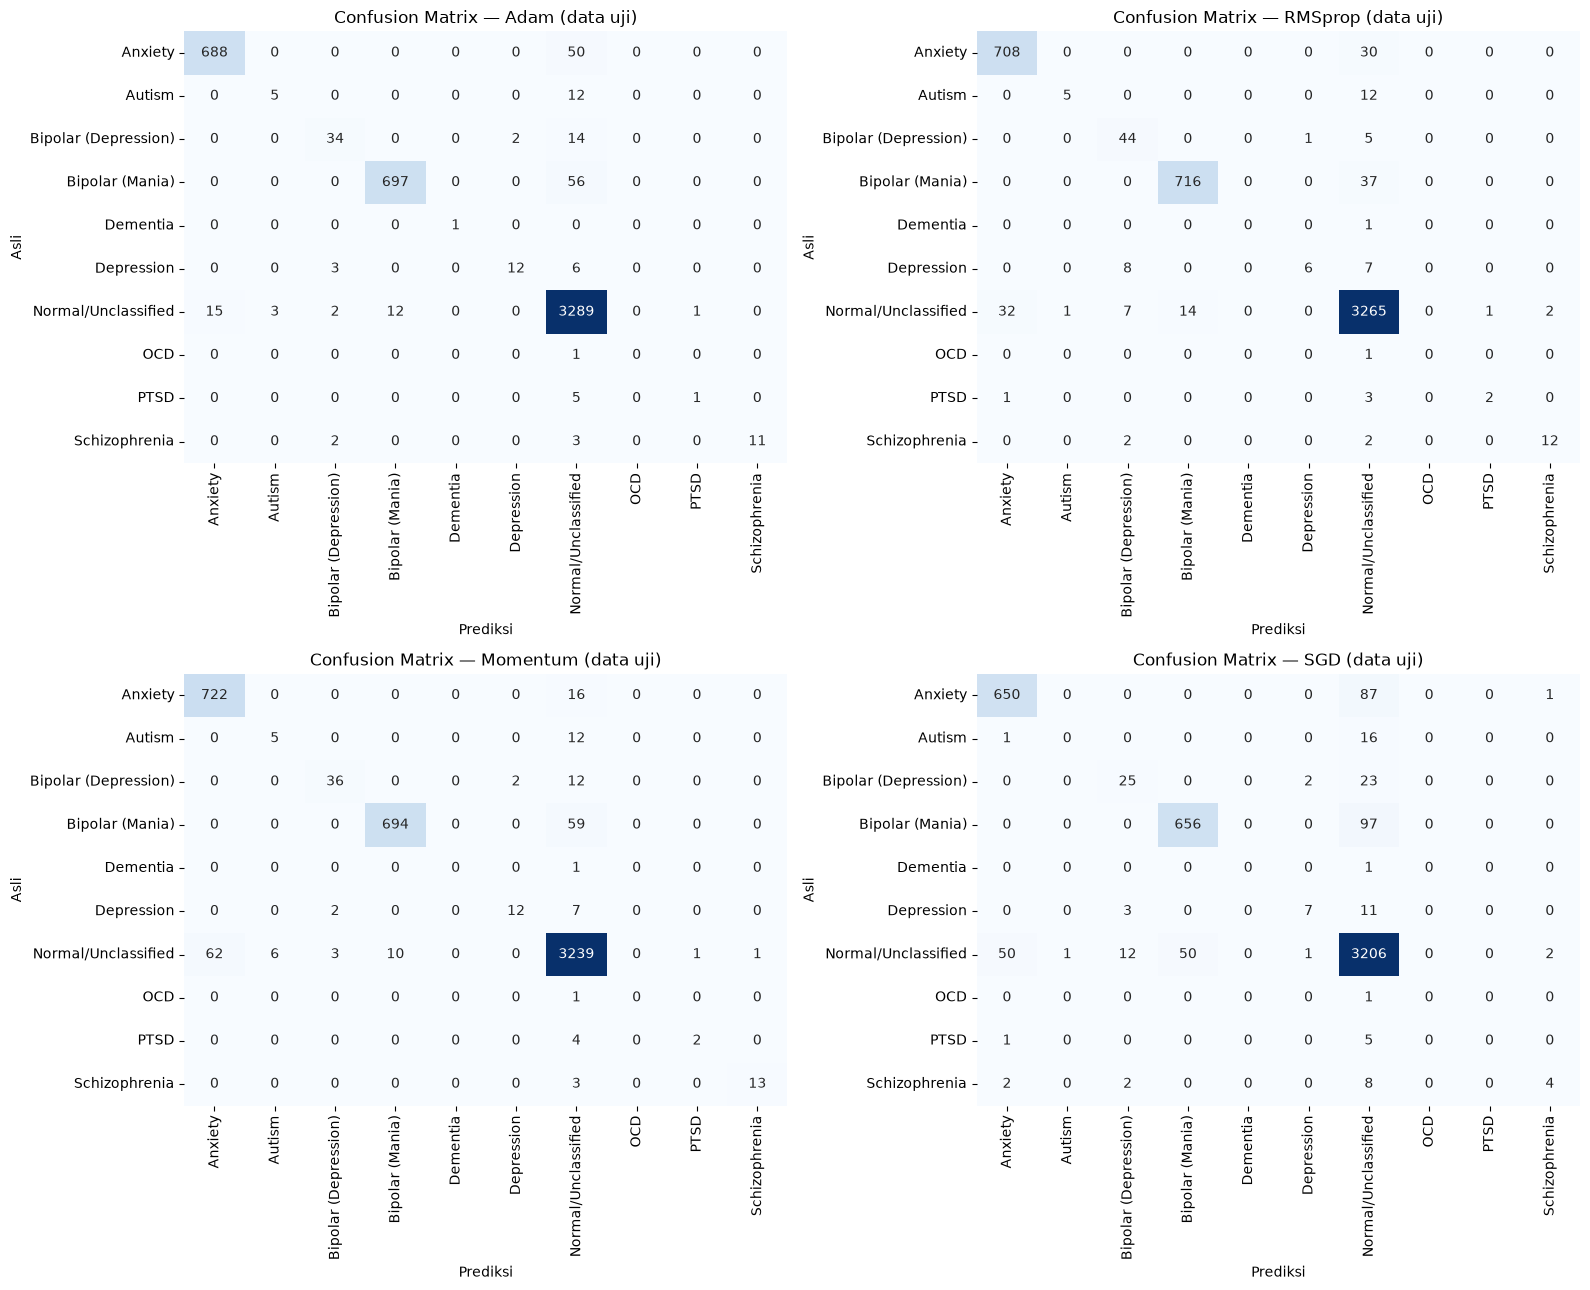

In [20]:
fig, axes = plt.subplots(2, 2, figsize=(16, 13))
for ax, name in zip(axes.flat, runs):
    cm = confusion_matrix(yte_true, preds_bank[name])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax, cbar=False,
                xticklabels=class_names, yticklabels=class_names)
    ax.set_xlabel("Prediksi")
    ax.set_ylabel("Asli")
    ax.set_title(f"Confusion Matrix — {name} (data uji)")
plt.tight_layout()
plt.show()

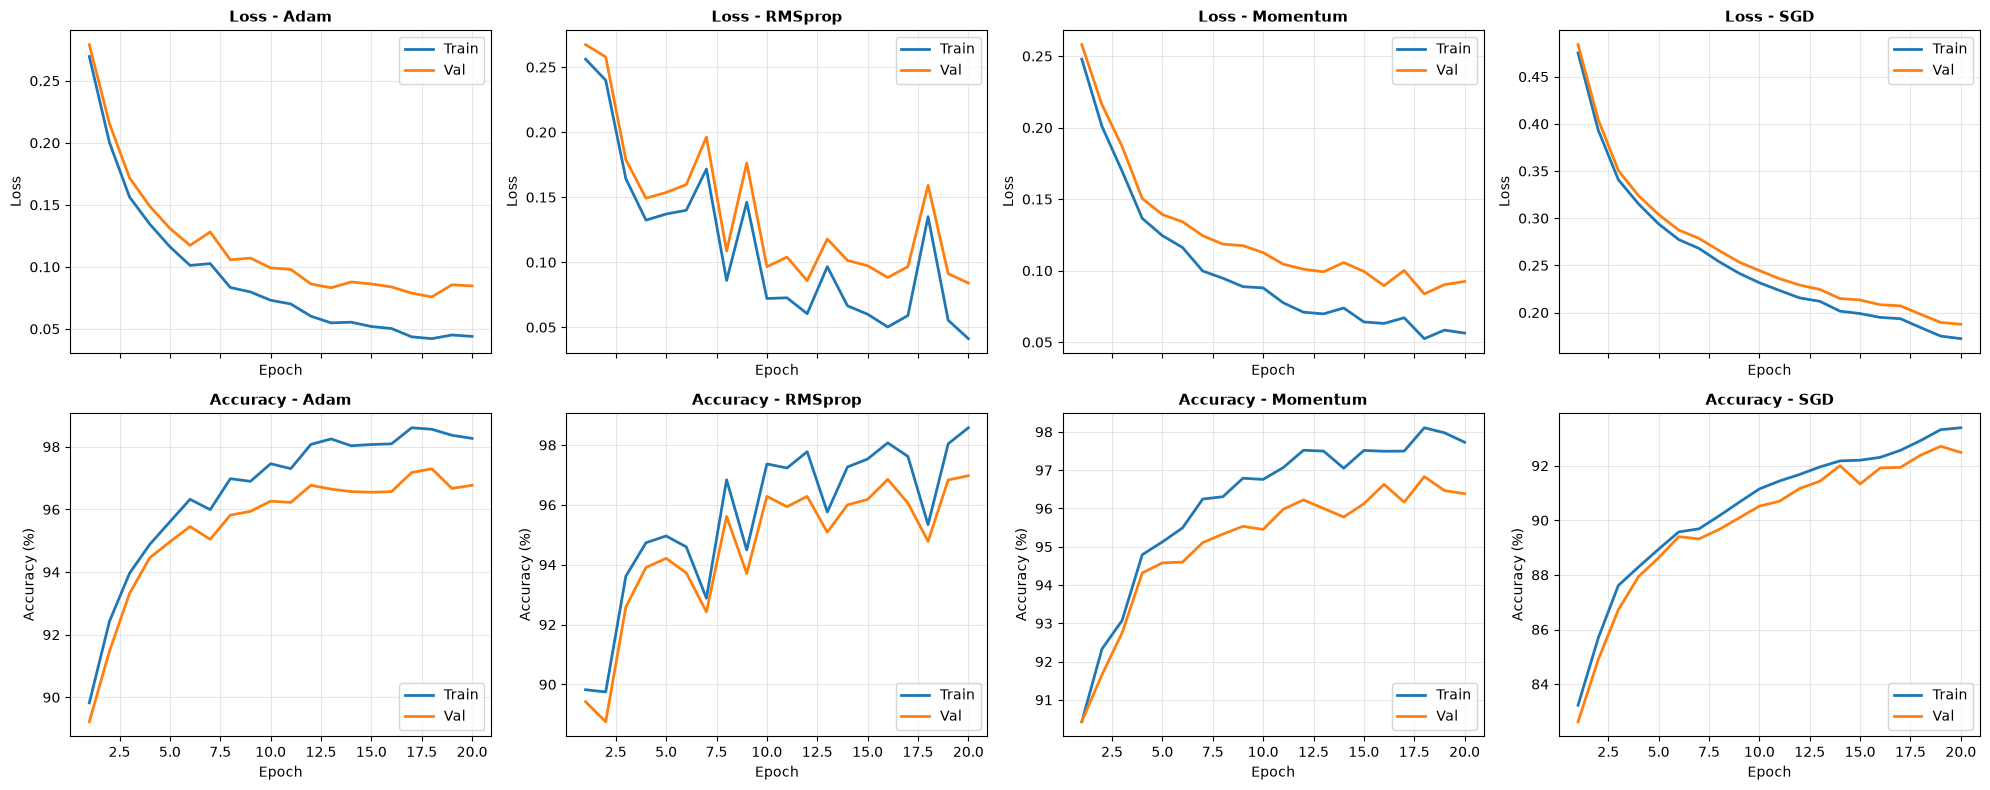

In [21]:
fig, axes = plt.subplots(2, 4, figsize=(20, 8), sharex=True)
epochs_axis = range(1, HYPERPARAMS["epochs"] + 1)

for idx, name in enumerate(runs):
    c = runs[name].epoch_curves

    ax_loss = axes[0, idx]
    ax_loss.plot(epochs_axis, c["train_loss"], label="Train", color="#1f77b4", linewidth=2)
    ax_loss.plot(epochs_axis, c["val_loss"], label="Val", color="#ff7f0e", linewidth=2)
    ax_loss.set_title(f"Loss - {name}", fontsize=11, fontweight="bold")
    ax_loss.set_xlabel("Epoch")
    ax_loss.set_ylabel("Loss")
    ax_loss.legend(loc="upper right")
    ax_loss.grid(True, alpha=0.3)

    ax_acc = axes[1, idx]
    ax_acc.plot(epochs_axis, np.array(c["train_acc"]) * 100, label="Train", color="#1f77b4", linewidth=2)
    ax_acc.plot(epochs_axis, np.array(c["val_acc"]) * 100, label="Val", color="#ff7f0e", linewidth=2)
    ax_acc.set_title(f"Accuracy - {name}", fontsize=11, fontweight="bold")
    ax_acc.set_xlabel("Epoch")
    ax_acc.set_ylabel("Accuracy (%)")
    ax_acc.legend(loc="lower right")
    ax_acc.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()